# Ghost Storefronts: visit records and staleness

The unit is one eligible inspection document, not an identified physical trip. Positive observations are compliant, violation or warning outcomes. All history comes strictly before each visit timestamp. 2026 is partial through August 23.

In [1]:
import os
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(root)
os.environ["OMP_NUM_THREADS"] = "4"
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from storefronts.notebook_tools import finish, style, table

style()

The eligible unit is a storefront inspection document with a business identity and strictly earlier history. A business can contribute several documents at the same timestamp, so these counts describe records rather than identified physical trips. Grouping equal timestamps prevents one outcome from predicting another record in the same block.

## Q1. Annual volume

The vertical line marks the June/July 2023 record-system switch.

[{'$group': {'_id': {'year': '$year', 'source': '$source'},
             'visits': {'$sum': 1},
             'oob': {'$sum': {'$cond': ['$target_oob', 1, 0]}},
             'violations': {'$sum': {'$cond': ['$target_violation', 1, 0]}},
             'first_visits': {'$sum': {'$cond': ['$is_first_visit', 1, 0]}},
             'oob_unknown_positive': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                   {'$not': ['$has_prior_positive']}]},
                                                         1,
                                                         0]}},
             'repeat_unresolved_oob': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                    '$prior_oob_unresolved']},
                                                          1,
                                                          0]}},
             'oob_old12': {'$sum': {'$cond': [{'$and': ['$target_oob', '$o

,visits,oob,violations,first_visits,oob_unknown_positive,repeat_unresolved_oob,oob_old12,oob_old24,oob_old36,oob_share,violation_share,year,source
0,70363,3200,17000,46208,2798,245,0,0,0,0.045478,0.241604,2010,archive
1,83388,4246,27315,33633,2391,841,463,0,0,0.050919,0.327565,2011,archive
2,82165,2574,26695,23670,816,358,635,75,0,0.031327,0.324895,2012,archive
3,79242,4038,24208,20006,1148,612,1576,728,107,0.050958,0.305495,2013,archive
4,68579,4696,13531,17617,1011,589,2600,1659,306,0.068476,0.197305,2014,archive
5,71345,6741,13725,15649,1165,1223,4160,2113,333,0.094485,0.192375,2015,archive
6,78764,8102,15528,14021,1271,1554,5366,3072,1059,0.102864,0.197146,2016,archive
7,77725,7408,17377,12723,1024,1593,4741,2444,1138,0.095310,0.223570,2017,archive
8,67413,8950,14790,11500,1123,1665,6326,4321,3161,0.132764,0.219394,2018,archive
9,65916,9448,16340,10547,1032,2037,7125,5375,4132,0.143334,0.247891,2019,archive


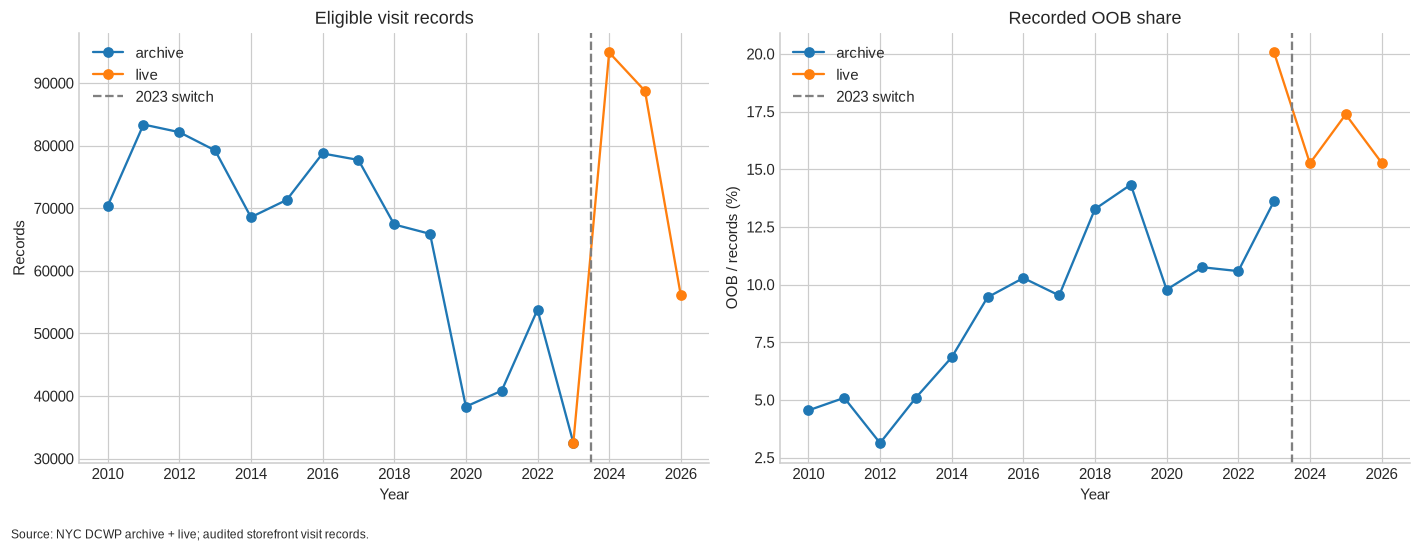

[{'$group': {'_id': {'year': '$year',
                     'source': '$source',
                     'bid': '$business_id',
                     't': '$inspected_at'},
             'records': {'$sum': 1},
             'outcomes': {'$addToSet': '$target_oob'}}},
 {'$group': {'_id': {'year': '$_id.year', 'source': '$_id.source'},
             'blocks': {'$sum': 1},
             'records': {'$sum': '$records'},
             'repeated_block_records': {'$sum': {'$cond': [{'$gt': ['$records', 1]},
                                                           '$records',
                                                           0]}}}},
 {'$sort': {'_id.year': 1, '_id.source': 1}}]


,blocks,records,repeated_block_records,year,source
0,57785,70363,21194,2010,archive
1,64084,83388,31511,2011,archive
2,65237,82165,28803,2012,archive
3,65235,79242,23906,2013,archive
4,68547,68579,64,2014,archive
5,71314,71345,62,2015,archive
6,78728,78764,72,2016,archive
7,77685,77725,80,2017,archive
8,63764,67413,6891,2018,archive
9,58145,65916,14844,2019,archive


[{'$match': {'year': 2023}},
 {'$group': {'_id': {'source': '$source', 'month': '$month'},
             'visits': {'$sum': 1},
             'oob': {'$sum': {'$cond': ['$target_oob', 1, 0]}},
             'violations': {'$sum': {'$cond': ['$target_violation', 1, 0]}},
             'first_visits': {'$sum': {'$cond': ['$is_first_visit', 1, 0]}},
             'oob_unknown_positive': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                   {'$not': ['$has_prior_positive']}]},
                                                         1,
                                                         0]}},
             'repeat_unresolved_oob': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                    '$prior_oob_unresolved']},
                                                          1,
                                                          0]}},
             'oob_old12': {'$sum': {'$cond'

,visits,oob,violations,first_visits,oob_unknown_positive,repeat_unresolved_oob,oob_old12,oob_old24,oob_old36,oob_share,violation_share,source,month
0,4673,388,1182,787,84,43,180,140,112,0.083030,0.252942,archive,1
1,5550,402,1318,660,92,35,197,148,131,0.072432,0.237477,archive,2
2,5848,783,1387,722,95,41,558,480,424,0.133892,0.237175,archive,3
3,4854,752,1269,651,48,55,563,528,493,0.154924,0.261434,archive,4
4,6069,1086,1287,719,51,60,922,888,851,0.178942,0.212061,archive,5
5,5558,1023,1193,707,66,70,862,828,798,0.184059,0.214646,archive,6
6,4538,724,1017,587,66,44,563,533,517,0.159542,0.224108,live,7
7,6334,1028,1578,857,85,181,759,677,637,0.162299,0.249132,live,8
8,5282,1190,1195,990,155,189,878,800,754,0.225293,0.226240,live,9
9,5797,1229,1327,880,108,229,969,878,828,0.212006,0.228912,live,10


In [2]:
yearly = table("eda.yearly")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for source, f in yearly.groupby("source"):
    axes[0].plot(f.year, f.visits, marker="o", label=source)
    axes[1].plot(f.year, 100 * f.oob_share, marker="o", label=source)
for ax in axes:
    ax.axvline(2023.5, color="grey", linestyle="--", label="2023 switch")
    ax.legend()
axes[0].set(title="Eligible visit records", xlabel="Year", ylabel="Records")
finish(axes[1], "Recorded OOB share", "Year", "OOB / records (%)")
blocks = table("eda.timestamp_blocks")
monthly = table("eda.monthly_2023")

Recorded OOB outcomes rose from about 3 to 5% of storefront visit records in 2010 to 2013 to 14.3% in 2019. Rates were about 10% in 2020 to 2022; visit volume initially fell 41.9% in 2020 relative to 2019. Live-system rates reached 15 to 17%, including 17.4% in 2025. The split 2023 year shows 13.6% in the archive and 20.1% in live data, but does not isolate a switch effect. Monthly OOB share rose from 7.2% in February to 13.4% in March, inside the archive; June was 18.4% and July 16.0%, without an upward boundary jump. Every OOB outcome requires a visit, so this series measures what inspectors recorded, not how fast NYC storefronts closed. Program mix and which businesses are visited can move it alongside business conditions.

## Q2. Live inspection programs

Program names do not establish the purpose of dispatch.

[{'$match': {'source': 'live'}},
 {'$group': {'_id': {'inspection_type': '$inspection_type'},
             'visits': {'$sum': 1},
             'oob': {'$sum': {'$cond': ['$target_oob', 1, 0]}},
             'violations': {'$sum': {'$cond': ['$target_violation', 1, 0]}},
             'first_visits': {'$sum': {'$cond': ['$is_first_visit', 1, 0]}},
             'oob_unknown_positive': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                   {'$not': ['$has_prior_positive']}]},
                                                         1,
                                                         0]}},
             'repeat_unresolved_oob': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                    '$prior_oob_unresolved']},
                                                          1,
                                                          0]}},
             'oob_old12': {'$sum': {'$co

,visits,oob,violations,first_visits,oob_unknown_positive,repeat_unresolved_oob,oob_old12,oob_old24,oob_old36,oob_share,violation_share,inspection_type
0,99481,27697,23841,10645,1466,3195,24909,22543,20541,0.278415,0.239654,Patrol
1,44144,4777,7538,2422,388,685,1626,605,389,0.108214,0.170759,Tobacco - Sale to Minor
2,37916,4651,7106,3724,462,611,2038,851,640,0.122666,0.187414,Tobacco - Adult Inspection
3,32380,3319,12126,6269,947,653,841,465,336,0.102502,0.374490,Tobacco - T21
4,6684,1068,3051,2778,741,42,215,162,137,0.159785,0.456463,Consumer Request to Inspect
5,19689,1000,615,2778,112,96,705,511,396,0.050790,0.031236,Scale
6,2128,926,419,50,51,223,647,450,187,0.435150,0.196898,Check UNL - FTR
7,3222,793,761,1300,458,47,247,188,168,0.246120,0.236189,Sweep
8,776,200,287,550,181,8,7,5,5,0.257732,0.369845,Legal Case-Related
9,12751,118,0,6473,94,5,7,4,1,0.009254,0.000000,Business Education


,inspection_type,visits,oob,oob_share,share_of_live_oob
0,Patrol,99481,27697,0.278415,0.615516
1,Tobacco - Sale to Minor,44144,4777,0.108214,0.106160
2,Tobacco - Adult Inspection,37916,4651,0.122666,0.103360
3,Tobacco - T21,32380,3319,0.102502,0.073759
4,Consumer Request to Inspect,6684,1068,0.159785,0.023734
5,Scale,19689,1000,0.050790,0.022223
6,Check UNL - FTR,2128,926,0.435150,0.020579
7,Sweep,3222,793,0.246120,0.017623
8,Legal Case-Related,776,200,0.257732,0.004445
9,Business Education,12751,118,0.009254,0.002622


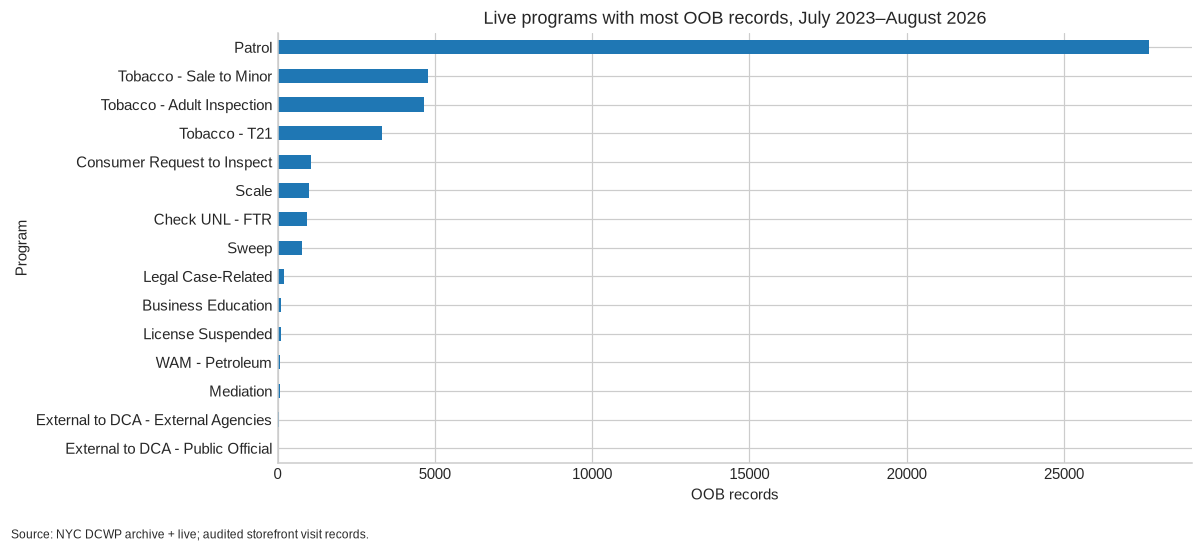

In [3]:
programs = table("eda.programs")
programs["share_of_live_oob"] = programs.oob / programs.oob.sum()
display(programs[["inspection_type", "visits", "oob", "oob_share", "share_of_live_oob"]])
ax = programs.head(15).sort_values("oob").plot.barh(x="inspection_type", y="oob", legend=False)
finish(ax, "Live programs with most OOB records, July 2023–August 2026", "OOB records", "Program")

Patrol visits produce 61.6% of all live OOB records, at a 27.8% rate. The three tobacco programs record OOB on about 10 to 12% of visits, and Business Education on under 1%. Check UNL - FTR records OOB on 43.5% of visits, the highest of any program with at least 1,000 records. Its name is consistent with checking a flagged or unlicensed business, but does not establish that purpose for individual records. The variation across programs is large enough that comparisons across years or neighborhoods have to account for program mix. Program names do not reveal dispatch intent, so these rates cannot separate intended closure confirmations from unexpected ones.

## Q3. Prior positive observation age

Unknown ages are a separate bin. Calendar-month thresholds use MongoDB dateSubtract; continuous months use 30.4375 days.

[{'$match': {'target_oob': True}},
 {'$set': {'age_bin': {'$switch': {'branches': [{'case': {'$eq': ['$months_since_last_positive',
                                                                  None]},
                                                 'then': 'Unknown'},
                                                {'case': {'$lte': ['$months_since_last_positive',
                                                                   12]},
                                                 'then': '0-12'},
                                                {'case': {'$lte': ['$months_since_last_positive',
                                                                   24]},
                                                 'then': '12-24'},
                                                {'case': {'$lte': ['$months_since_last_positive',
                                                                   36]},
                                                 'then': '24-36'},
            

,oob,year,age_bin
0,402,2010,0-12
1,2798,2010,Unknown
2,1392,2011,0-12
3,463,2011,12-24
4,2391,2011,Unknown
...,...,...,...
93,687,2026,120+
94,735,2026,24-36
95,651,2026,36-60
96,2731,2026,60-120


,visits,oob,oob_unknown_positive,oob_old12,oob_old24,oob_old36,oob_old12_share,oob_old24_share,oob_old36_share
year,,,,,,,,,
2010,70363,3200,2798,0,0,0,0.000000,0.000000,0.000000
2011,83388,4246,2391,463,0,0,0.109044,0.000000,0.000000
2012,82165,2574,816,635,75,0,0.246698,0.029138,0.000000
2013,79242,4038,1148,1576,728,107,0.390292,0.180287,0.026498
2014,68579,4696,1011,2600,1659,306,0.553663,0.353279,0.065162
2015,71345,6741,1165,4160,2113,333,0.617119,0.313455,0.049399
2016,78764,8102,1271,5366,3072,1059,0.662306,0.379166,0.130708
2017,77725,7408,1024,4741,2444,1138,0.639984,0.329914,0.153618
2018,67413,8950,1123,6326,4321,3161,0.706816,0.482793,0.353184


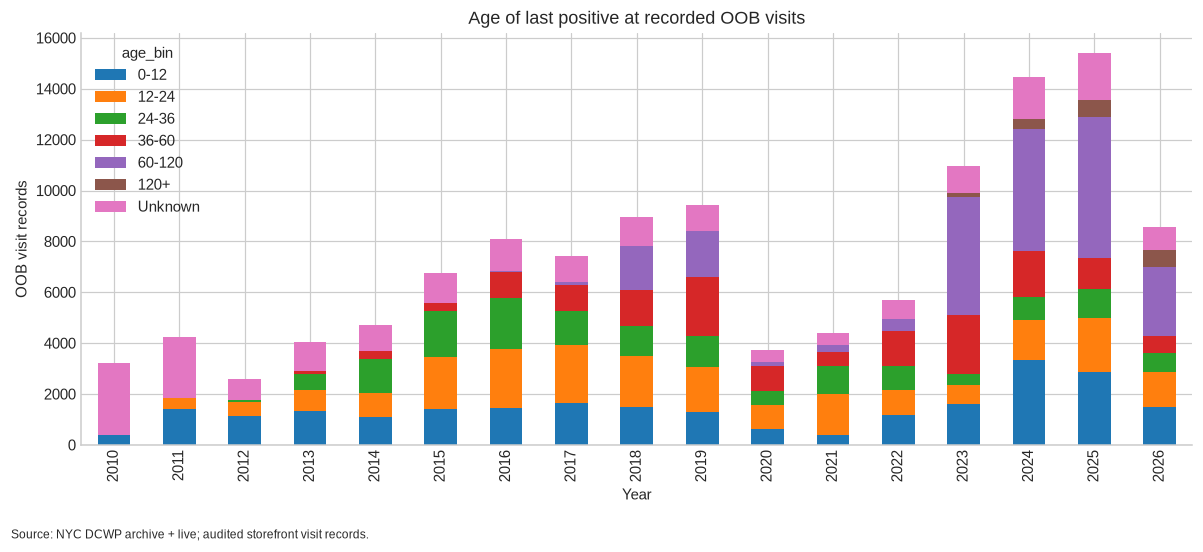

[{'$match': {'year': 2025}},
 {'$group': {'_id': None,
             'visits': {'$sum': 1},
             'known_old24_visits': {'$sum': {'$cond': ['$old24', 1, 0]}},
             'known_old24_oob': {'$sum': {'$cond': [{'$and': ['$old24', '$target_oob']}, 1, 0]}}}}]


,_id,visits,known_old24_visits,known_old24_oob
0,None,88745,21596,8597


,_id,visits,known_old24_visits,known_old24_oob,oob_share_known_old24
0,None,88745,21596,8597,0.398083


In [4]:
staleness = table("eda.staleness")
years = yearly.groupby("year").sum(numeric_only=True)
for m in [12, 24, 36]:
    years[f"oob_old{m}_share"] = years[f"oob_old{m}"] / years.oob
display(
    years[
        [
            "visits",
            "oob",
            "oob_unknown_positive",
            "oob_old12",
            "oob_old24",
            "oob_old36",
            "oob_old12_share",
            "oob_old24_share",
            "oob_old36_share",
        ]
    ]
)
order = ["0-12", "12-24", "24-36", "36-60", "60-120", "120+", "Unknown"]
ax = (
    staleness.pivot(index="year", columns="age_bin", values="oob")
    .reindex(columns=order)
    .plot.bar(stacked=True)
)
finish(ax, "Age of last positive at recorded OOB visits", "Year", "OOB visit records")
prior_age = table("eda.prior_age_counts")
prior_age["oob_share_known_old24"] = prior_age.known_old24_oob / prior_age.known_old24_visits
display(prior_age)

In 2025, 7,442 of 15,423 OOB records (48.3%) concerned a business whose last positive observation was more than three years before the visit, and 8,597 (55.7%) were more than two years stale. Of 21,596 visits to businesses whose last positive was over 24 months old, 39.8% ended in OOB, against a 17.4% base rate. This is the core evidence that identities keep appearing in inspection records long after the last sign they were operating. Early years show small long-staleness shares partly because the data begin in 2010, so a 36-month gap cannot appear before 2013.

## Q4. Repeat OOB without an intervening positive

A positive at the same timestamp as an OOB record is not a later positive. Earlier OOB does not prove permanent cessation.

[{'$group': {'_id': {'year': '$year', 'source': '$source'},
             'visits': {'$sum': 1},
             'oob': {'$sum': {'$cond': ['$target_oob', 1, 0]}},
             'violations': {'$sum': {'$cond': ['$target_violation', 1, 0]}},
             'first_visits': {'$sum': {'$cond': ['$is_first_visit', 1, 0]}},
             'oob_unknown_positive': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                   {'$not': ['$has_prior_positive']}]},
                                                         1,
                                                         0]}},
             'repeat_unresolved_oob': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                    '$prior_oob_unresolved']},
                                                          1,
                                                          0]}},
             'oob_old12': {'$sum': {'$cond': [{'$and': ['$target_oob', '$o

,visits,oob,violations,first_visits,oob_unknown_positive,repeat_unresolved_oob,oob_old12,oob_old24,oob_old36,oob_share,violation_share,year,source
0,70363,3200,17000,46208,2798,245,0,0,0,0.045478,0.241604,2010,archive
1,83388,4246,27315,33633,2391,841,463,0,0,0.050919,0.327565,2011,archive
2,82165,2574,26695,23670,816,358,635,75,0,0.031327,0.324895,2012,archive
3,79242,4038,24208,20006,1148,612,1576,728,107,0.050958,0.305495,2013,archive
4,68579,4696,13531,17617,1011,589,2600,1659,306,0.068476,0.197305,2014,archive
5,71345,6741,13725,15649,1165,1223,4160,2113,333,0.094485,0.192375,2015,archive
6,78764,8102,15528,14021,1271,1554,5366,3072,1059,0.102864,0.197146,2016,archive
7,77725,7408,17377,12723,1024,1593,4741,2444,1138,0.095310,0.223570,2017,archive
8,67413,8950,14790,11500,1123,1665,6326,4321,3161,0.132764,0.219394,2018,archive
9,65916,9448,16340,10547,1032,2037,7125,5375,4132,0.143334,0.247891,2019,archive


,year,source,visits,oob,repeat_unresolved_oob
0,2010,archive,70363,3200,245
1,2011,archive,83388,4246,841
2,2012,archive,82165,2574,358
3,2013,archive,79242,4038,612
4,2014,archive,68579,4696,589
5,2015,archive,71345,6741,1223
6,2016,archive,78764,8102,1554
7,2017,archive,77725,7408,1593
8,2018,archive,67413,8950,1665
9,2019,archive,65916,9448,2037


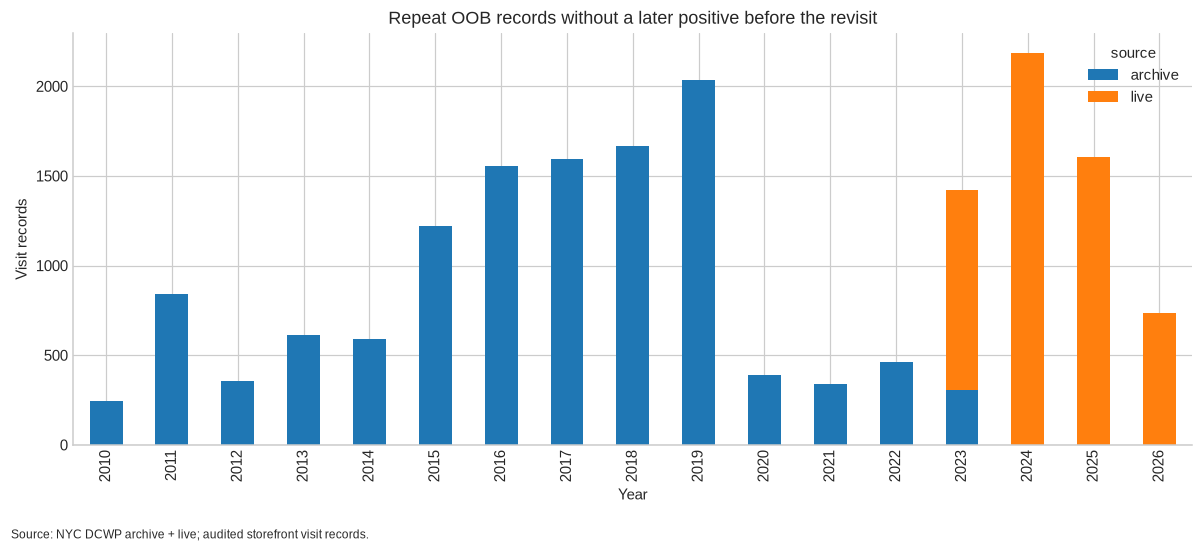

In [5]:
yearly = table("eda.yearly")
display(yearly[["year", "source", "visits", "oob", "repeat_unresolved_oob"]])
ax = yearly.pivot(index="year", columns="source", values="repeat_unresolved_oob").plot.bar(
    stacked=True
)
finish(
    ax, "Repeat OOB records without a later positive before the revisit", "Year", "Visit records"
)

Visits to businesses already recorded OOB, with no positive observation since, numbered 2,037 in 2019, 2,188 in 2024 and 1,603 in 2025, between about 10% and 22% of those years' OOB records. These are the clearest candidates for pre-dispatch review: the record already reports OOB and no later positive contradicts it. Some may be legitimate follow-ups, such as license cancellation or enforcement steps. The data carry no dispatch reasons, so this count is an upper bound on avoidable repeats within this subset, not a measured amount of unnecessary work.

## Q5. Industry

Industry is from the latest strictly earlier observation; cold starts are UNKNOWN. Counts reflect the inspected population.

[{'$match': {'$or': [{'year': 2025}, {'year': {'$gte': 2015, '$lte': 2019}}]}},
 {'$set': {'period': {'$cond': [{'$eq': ['$year', 2025]}, '2025', '2015-2019']}}},
 {'$group': {'_id': {'period': '$period', 'industry_group': '$industry_group'},
             'visits': {'$sum': 1},
             'oob': {'$sum': {'$cond': ['$target_oob', 1, 0]}},
             'violations': {'$sum': {'$cond': ['$target_violation', 1, 0]}},
             'first_visits': {'$sum': {'$cond': ['$is_first_visit', 1, 0]}},
             'oob_unknown_positive': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                   {'$not': ['$has_prior_positive']}]},
                                                         1,
                                                         0]}},
             'repeat_unresolved_oob': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                    '$prior_oob_unresolved']},
                

,visits,oob,violations,first_visits,oob_unknown_positive,repeat_unresolved_oob,oob_old12,oob_old24,oob_old36,oob_share,violation_share,period,industry_group
0,64440,4330,15612,64440,4330,0,0,0,0,0.067194,0.242272,2015-2019,UNKNOWN
1,15131,662,4611,0,45,126,457,243,116,0.043751,0.304739,2015-2019,auto_fuel_parking
2,303,24,35,0,8,2,13,10,7,0.079208,0.115512,2015-2019,entertainment
3,72903,6776,19579,0,145,1908,5145,2806,1386,0.092945,0.268562,2015-2019,food_grocery
4,55977,10708,8081,0,268,1121,9611,7229,4310,0.191293,0.144363,2015-2019,general_retail
5,15,1,3,0,0,1,1,1,0,0.066667,0.200000,2015-2019,missing
6,663,40,102,0,1,6,27,20,13,0.060332,0.153846,2015-2019,other
7,37199,5817,5873,0,199,481,5095,3882,2501,0.156375,0.157881,2015-2019,personal_services
8,2124,207,376,0,2,36,140,79,45,0.097458,0.177024,2015-2019,product_rule_checks
9,16273,1495,2904,0,157,291,1112,629,274,0.091870,0.178455,2015-2019,secondhand_pawn


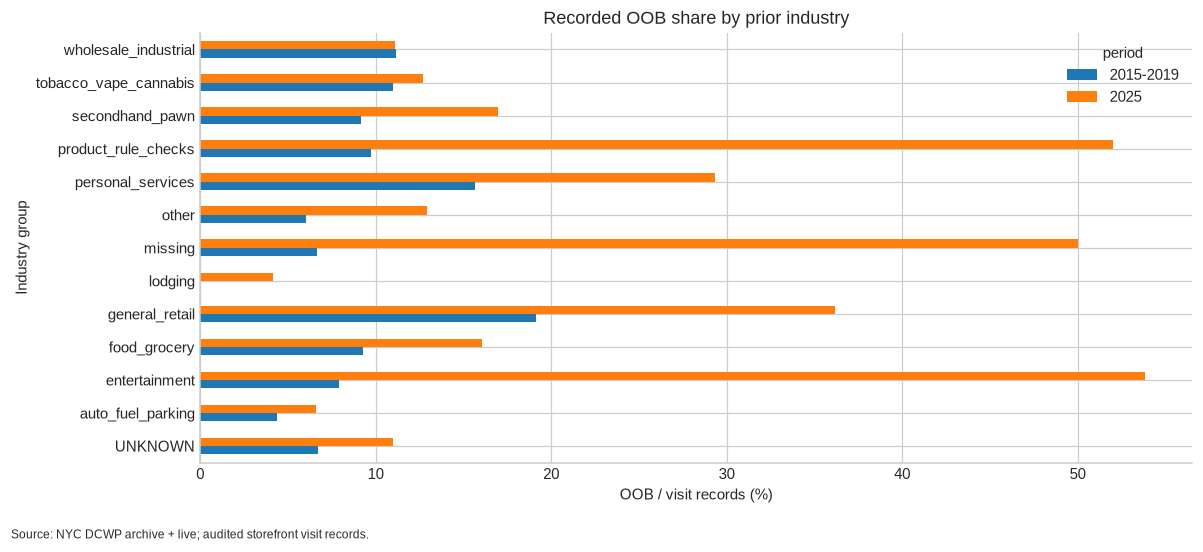

In [6]:
industry = table("eda.industry")
ax = (
    industry.pivot(index="industry_group", columns="period", values="oob_share")
    .mul(100)
    .plot.barh()
)
finish(ax, "Recorded OOB share by prior industry", "OOB / visit records (%)", "Industry group")

In 2025, general retail had the highest OOB share among groups with at least 1,000 visits: 36.2% (4,241/11,728). Tobacco, vape and cannabis recorded 12.7% (4,435/34,942), despite having the most records among known industry groups. General retail's last positive was over 36 months old at 79.7% of its OOB visits (3,381/4,241), compared with 12.5% for tobacco, vape and cannabis (554/4,435). Differences in inspection frequency can contribute to this contrast, but these aggregates do not establish an effect on closure-detection timing. Between 2015 to 2019 and 2025, OOB shares rose from 19.1% to 36.2% in general retail (+17.0 points), 15.6% to 29.3% in personal services (+13.7), 9.3% to 16.1% in food and grocery (+6.8), and 11.0% to 12.7% in tobacco, vape and cannabis (+1.7).

## Q6. NTA 2020 geography

At least 500 eligible visit records in 2025 per displayed NTA. Current visit location is permitted because it can be known before dispatch. The CSV uses NTA 2020 codes to join neighborhood boundaries. These are inspection-outcome rates.

[{'$match': {'year': 2025, 'nta2020': {'$nin': [None, '']}}},
 {'$group': {'_id': {'nta2020': '$nta2020', 'nta_name': '$nta_name'},
             'visits': {'$sum': 1},
             'oob': {'$sum': {'$cond': ['$target_oob', 1, 0]}},
             'violations': {'$sum': {'$cond': ['$target_violation', 1, 0]}},
             'first_visits': {'$sum': {'$cond': ['$is_first_visit', 1, 0]}},
             'oob_unknown_positive': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                   {'$not': ['$has_prior_positive']}]},
                                                         1,
                                                         0]}},
             'repeat_unresolved_oob': {'$sum': {'$cond': [{'$and': ['$target_oob',
                                                                    '$prior_oob_unresolved']},
                                                          1,
                                                          0]}},
  

,visits,oob,violations,first_visits,oob_unknown_positive,repeat_unresolved_oob,oob_old12,oob_old24,oob_old36,oob_share,violation_share,nta2020,nta_name
0,1082,292,203,233,40,25,230,214,205,0.269871,0.187616,MN0201,SoHo-Little Italy-Hudson Square
1,783,205,151,131,27,21,132,114,107,0.261814,0.192848,MN1001,Harlem (South)
2,1074,271,187,173,32,25,224,205,198,0.252328,0.174115,MN0802,Upper East Side-Carnegie Hill
3,1358,338,231,302,52,21,270,244,222,0.248895,0.170103,QN0707,Flushing-Willets Point
4,842,207,130,127,15,22,177,167,140,0.245843,0.154394,QN0602,Forest Hills
5,1228,300,212,241,36,32,233,208,197,0.244300,0.172638,MN0501,Midtown South-Flatiron-Union Square
6,504,123,111,66,27,16,70,50,48,0.244048,0.220238,MN0703,Upper West Side-Manhattan Valley
7,528,126,101,100,24,16,88,76,65,0.238636,0.191288,MN0202,Greenwich Village
8,910,215,161,142,19,22,166,148,131,0.236264,0.176923,MN1201,Washington Heights (South)
9,816,180,135,138,33,33,116,88,73,0.220588,0.165441,MN0101,Financial District-Battery Park City


Boundary features: 262 ; example properties: {':id': 'row-bmvw_d9i9~nqb4', ':version': 'rv-i7ie.ap2h_d5bw', ':created_at': '2026-05-28T15:11:18.238Z', ':updated_at': '2026-05-28T15:11:18.238Z', 'borocode': '3', 'boroname': 'Brooklyn', 'countyfips': '047', 'nta2020': 'BK0101', 'ntaname': 'Greenpoint', 'ntaabbrev': 'Grnpt', 'ntatype': '0', 'cdta2020': 'BK01', 'cdtaname': 'BK01 Williamsburg-Greenpoint (CD 1 Equivalent)', 'shape_leng': '28919.5607283', 'shape_area': '35321808.4385'}


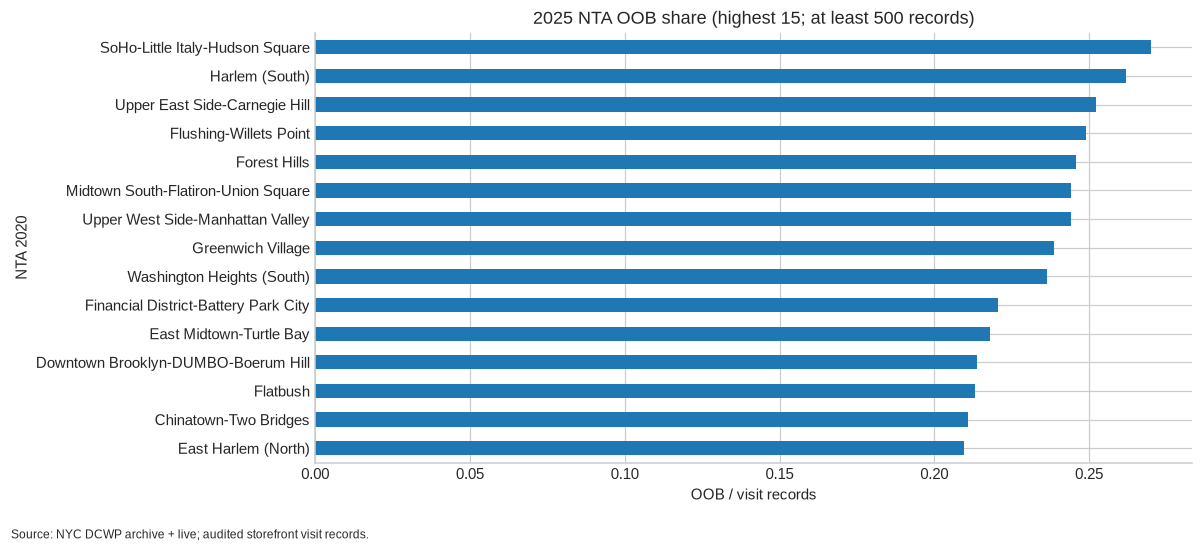

In [7]:
nta = table("eda.nta")
Path("exports").mkdir(exist_ok=True)
nta.to_csv("exports/nta_2025.csv", index=False)
import json

geo = json.loads(Path("data/boundaries/nta2020.geojson").read_text())
print(
    "Boundary features:",
    len(geo["features"]),
    "; example properties:",
    geo["features"][0]["properties"],
)
ax = nta.head(15).sort_values("oob_share").plot.barh(x="nta_name", y="oob_share", legend=False)
finish(
    ax, "2025 NTA OOB share (highest 15; at least 500 records)", "OOB / visit records", "NTA 2020"
)

Among NTAs with at least 500 visit records in 2025, the highest OOB shares are in Manhattan commercial districts, led by SoHo-Little Italy-Hudson Square (27.0%), Harlem (South) (26.2%) and Upper East Side-Carnegie Hill (25.2%). Flushing-Willets Point (24.9%) and Forest Hills (24.6%) lead the Queens areas. The pattern also reflects where inspectors are sent and the program mix each area receives. The map shows where OOB records surface, not actual business turnover or a ranking of neighborhood property conditions.

## Q7. Sample lineage

The sample is a city-archive slice joined by case ID and calendar day, not an independent survey. The copy loses time of day, coordinates, borough and unit. Numeric certificate conversion removes leading zeros. Some date strings are space-padded; parsing strips whitespace. Archive case IDs may repeat across reinspections.

[{'$match': {'source': 'archive', 'in_teaching_sample': True}}, {'$count': 'matched'}]


,matched
0,80040


[{'$count': 'sample_docs'}]


,sample_docs
0,80047


,sample_docs,archive_docs_flagged,match_share
0,80047,80040,0.999913


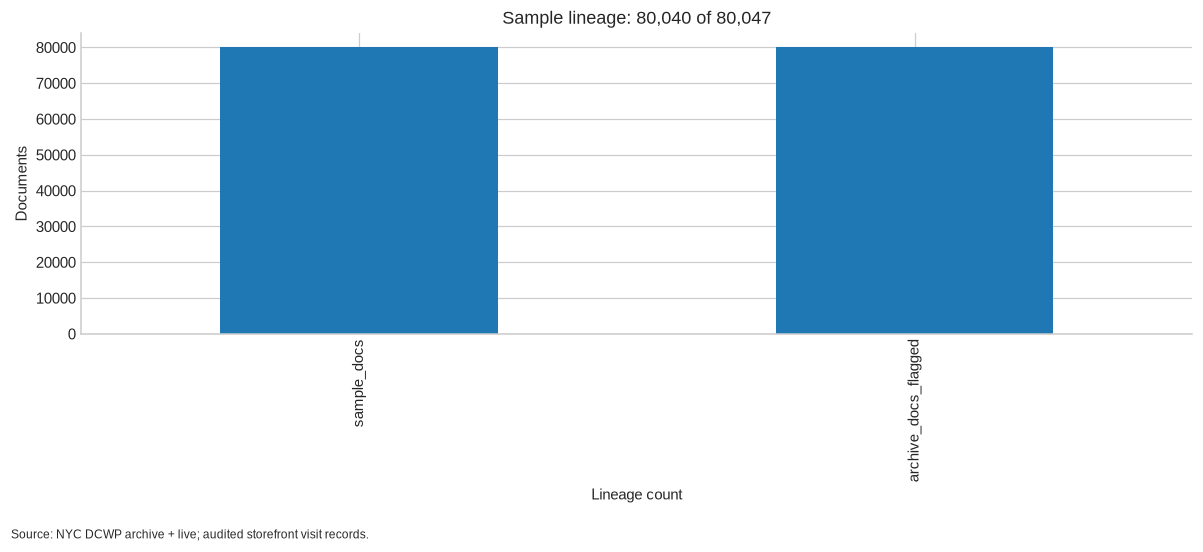

[{'$group': {'_id': None,
             'documents': {'$sum': 1},
             'fields': {'$addToSet': {'$map': {'input': {'$objectToArray': '$$ROOT'},
                                               'as': 'field',
                                               'in': '$$field.k'}}},
             'date_types': {'$addToSet': {'$type': '$date'}},
             'certificate_types': {'$addToSet': {'$type': '$certificate_number'}},
             'integer_certificates': {'$sum': {'$cond': [{'$eq': [{'$type': '$certificate_number'},
                                                                  'int']},
                                                         1,
                                                         0]}},
             'string_certificates': {'$sum': {'$cond': [{'$eq': [{'$type': '$certificate_number'},
                                                                 'string']},
                                                        1,
                                        

,_id,documents,fields,date_types,certificate_types,integer_certificates,string_certificates,address_fields,padded_day_dates
0,None,80047,"[[_id, id, certificate_number, business_name, ...",[string],"[int, string]",79894,153,"[[city, zip, street, number]]",22963


In [8]:
matched = table("eda.lineage", "inspections")
sample = table("eda.sample_count", "raw_sample_2015")
lineage = pd.DataFrame(
    {
        "sample_docs": [int(sample.sample_docs.iloc[0])],
        "archive_docs_flagged": [int(matched.matched.iloc[0])],
    }
)
lineage["match_share"] = lineage.archive_docs_flagged / lineage.sample_docs
display(lineage)
ax = lineage[["sample_docs", "archive_docs_flagged"]].T.plot.bar(legend=False)
finish(ax, "Sample lineage: 80,040 of 80,047", "Lineage count", "Documents")
formats = table("eda.sample_formats", "raw_sample_2015")

MongoDB's sample_training.inspections collection is a slice of the city archive: 80,040 of its 80,047 documents match an archive record on record ID and date. The 2015 copy drops time of day, coordinates, borough, unit and neighborhood codes. It stores dates as text, including space-padded single-digit days, and most certificate numbers as integers, which removes leading zeros; a small minority remain strings. The archive's rec_id is a case number shared by re-inspections, so it cannot serve as an inspection key. These details matter when joining the sample to other data, and they are why this project rebuilds the dataset from the source.